<a href="https://colab.research.google.com/github/anushka7519-sh-ig/SML-2-LAB-CODES/blob/main/EM%20class%20question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

sequences = [
    "HHHTHHHTHH",
    "TTHTTTHTTT",
    "HHHHTHHHHT",
    "TTTHTTTTHT",
    "HTHHHTHHTH"
]

data = []

for sequence in sequences:
    heads = sequence.count("H")
    tails = sequence.count("T")
    data.append([heads, tails])

df = pd.DataFrame(data, columns=["Heads", "Tails"], index=[f"Round {i}" for i in range(1, 6)])

df

,Heads,Tails
Round 1,8,2
Round 2,2,8
Round 3,8,2
Round 4,2,8
Round 5,7,3


In [2]:
theta_A = 0.6
theta_B = 0.4

pi_A = 0.5
pi_B = 0.5

max_iterations = 1000
tolerance = 1e-10

history = []

for iteration in range(max_iterations):

    old_A = theta_A
    old_B = theta_B

    heads = df["Heads"].values
    tails = df["Tails"].values

    likelihood_A = pi_A * (theta_A ** heads) * ((1 - theta_A) ** tails)
    likelihood_B = pi_B * (theta_B ** heads) * ((1 - theta_B) ** tails)

    responsibility_A = likelihood_A / (likelihood_A + likelihood_B)
    responsibility_B = 1 - responsibility_A

    expected_heads_A = np.sum(responsibility_A * heads)
    expected_tosses_A = np.sum(responsibility_A * (heads + tails))

    expected_heads_B = np.sum(responsibility_B * heads)
    expected_tosses_B = np.sum(responsibility_B * (heads + tails))

    theta_A = expected_heads_A / expected_tosses_A
    theta_B = expected_heads_B / expected_tosses_B

    history.append({
        "Iteration": iteration + 1,
        "Theta A": theta_A,
        "Theta B": theta_B,
        "Expected Heads A": expected_heads_A,
        "Expected Tosses A": expected_tosses_A,
        "Expected Heads B": expected_heads_B,
        "Expected Tosses B": expected_tosses_B
    })

    if abs(theta_A - old_A) < tolerance and abs(theta_B - old_B) < tolerance:
        break

results = pd.DataFrame(history)

results

,Iteration,Theta A,Theta B,Expected Heads A,Expected Tosses A,Expected Heads B,Expected Tosses B
0,1,0.736385,0.282830,20.876887,28.350515,6.123113,21.649485
1,2,0.766272,0.208044,22.783567,29.732990,4.216433,20.267010
2,3,0.766458,0.201254,22.968211,29.966701,4.031789,20.033299
3,4,0.766444,0.201015,22.974850,29.975886,4.025150,20.024114
4,5,0.766444,0.201007,22.975067,29.976194,4.024933,20.023806
5,6,0.766444,0.201007,22.975075,29.976204,4.024925,20.023796
6,7,0.766444,0.201007,22.975075,29.976204,4.024925,20.023796
7,8,0.766444,0.201007,22.975075,29.976204,4.024925,20.023796
8,9,0.766444,0.201007,22.975075,29.976204,4.024925,20.023796


In [3]:
likelihood_A = pi_A * (theta_A ** df["Heads"]) * ((1 - theta_A) ** df["Tails"])
likelihood_B = pi_B * (theta_B ** df["Heads"]) * ((1 - theta_B) ** df["Tails"])

responsibility_A = likelihood_A / (likelihood_A + likelihood_B)
responsibility_B = 1 - responsibility_A

responsibilities = pd.DataFrame({
    "Heads": df["Heads"],
    "Tails": df["Tails"],
    "P(Coin A)": responsibility_A,
    "P(Coin B)": responsibility_B
})

responsibilities

,Heads,Tails,P(Coin A),P(Coin B)
Round 1,8,2,0.999738,0.000262
Round 2,2,8,0.000774,0.999226
Round 3,8,2,0.999738,0.000262
Round 4,2,8,0.000774,0.999226
Round 5,7,3,0.996595,0.003405


In [4]:
print("Final Results")
print("--------------------")
print(f"Coin A Head Probability: {theta_A:.6f}")
print(f"Coin A Tail Probability: {1-theta_A:.6f}")
print(f"Coin B Head Probability: {theta_B:.6f}")
print(f"Coin B Tail Probability: {1-theta_B:.6f}")
print(f"Total Iterations: {len(history)}")

Final Results
--------------------
Coin A Head Probability: 0.766444
Coin A Tail Probability: 0.233556
Coin B Head Probability: 0.201007
Coin B Tail Probability: 0.798993
Total Iterations: 9


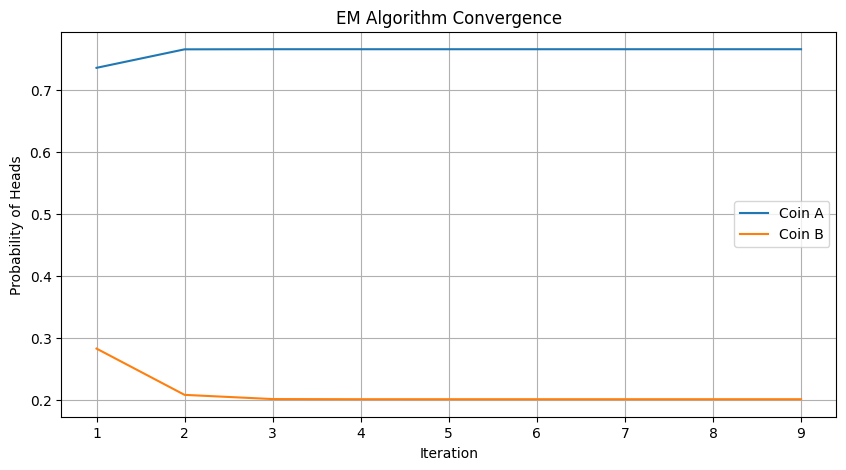

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(results["Iteration"], results["Theta A"], label="Coin A")
plt.plot(results["Iteration"], results["Theta B"], label="Coin B")

plt.xlabel("Iteration")
plt.ylabel("Probability of Heads")
plt.title("EM Algorithm Convergence")
plt.legend()
plt.grid(True)
plt.show()

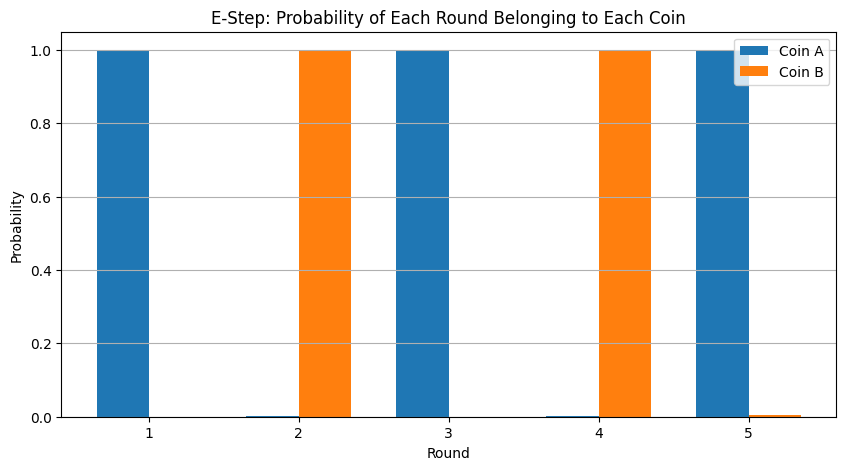

In [6]:
plt.figure(figsize=(10, 5))

x = np.arange(1, 6)
width = 0.35

plt.bar(x - width/2, responsibility_A, width, label="Coin A")
plt.bar(x + width/2, responsibility_B, width, label="Coin B")

plt.xlabel("Round")
plt.ylabel("Probability")
plt.title("E-Step: Probability of Each Round Belonging to Each Coin")
plt.xticks(x)
plt.legend()
plt.grid(axis="y")
plt.show()